# Live demo - predicting PROMIS physical-health decline during chemotherapy
Replication of *Ostberg & Peterson, CS229 Spring 2020*.

Run `python -m prodecline all` (or `all --fast`) once before this notebook; it loads the saved cohort, features and trained models.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score
from prodecline.config import CONFIG as cfg
from prodecline.pipeline import load_dataset
pd.set_option('display.width', 140)
X, cohort, split = load_dataset(cfg)
tr, te = split.eq('train').to_numpy(), split.eq('test').to_numpy()
print(f'{len(cohort)} patients x {X.shape[1]} raw features | train {tr.sum()} / test {te.sum()}')

1254 patients x 852 raw features | train 1003 / test 251


## 1. Cohort construction (inclusion criteria)

In [2]:
pd.read_csv(cfg.paths.processed_dir / 'cohort_flow.csv')

,step,n_patients
0,All patients in extract,1715
1,Cancer diagnosis on/after 2013-01-01,1493
2,Received chemotherapy,1493
3,Baseline PROMIS survey <= 90 d before chemo,1393
4,On-treatment PROMIS survey 30-180 d after chem...,1254


## 2. Outcomes
*Drop*: GPH falls by >= 10 points (1 SD). *Threshold*: on-treatment GPH <= 40.

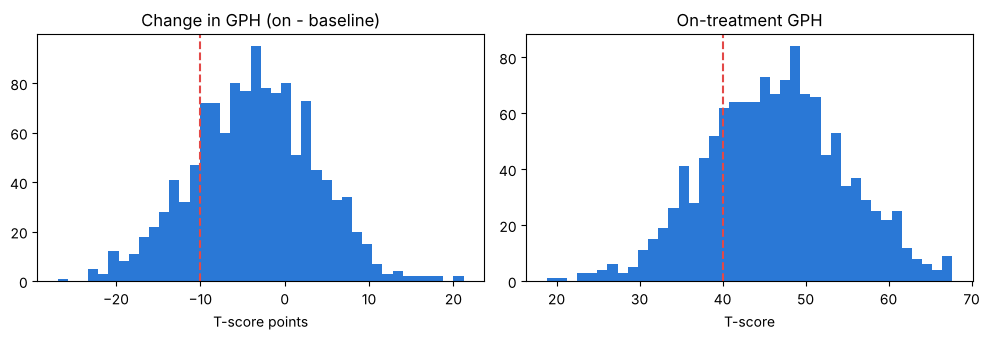

,prevalence
drop,0.185008
threshold,0.225678


In [3]:
change = cohort.gph_on_treatment - cohort.gph_baseline
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(change, bins=40, color='#2a78d6'); ax[0].axvline(-10, color='#e34948', ls='--')
ax[0].set(title='Change in GPH (on - baseline)', xlabel='T-score points')
ax[1].hist(cohort.gph_on_treatment, bins=40, color='#2a78d6'); ax[1].axvline(40, color='#e34948', ls='--')
ax[1].set(title='On-treatment GPH', xlabel='T-score')
plt.tight_layout(); plt.show()
cohort[['drop', 'threshold']].mean().rename('prevalence').to_frame()

## 3. Feature groups (raw, before train-fold preprocessing)

In [4]:
X.columns.str.split('__').str[0].value_counts().rename('n_features').to_frame()

,n_features
proc,336
dx,320
med,121
lab,49
demo,8
vital,7
promis,6
util,5


## 4. Results (test set, 95% bootstrap CI)

In [5]:
m = pd.read_csv(cfg.paths.results_dir / 'metrics.csv')
m.pivot_table(index='model', columns=['outcome', 'lab_strategy'], values='test_auroc').round(3).sort_values(('drop', 'knn'), ascending=False)

outcome         drop        threshold       
lab_strategy  binned    knn    binned    knn
model                                       
elasticnet     0.714  0.717     0.868  0.866
lasso          0.730  0.699     0.840  0.851
ensemble       0.716  0.692     0.863  0.868
lightgbm       0.709  0.688     0.840  0.854
ridge          0.676  0.638     0.843  0.841
random_forest  0.653  0.634     0.849  0.851
svm            0.643  0.619     0.806  0.833
knn            0.553  0.560     0.772  0.809
mlp            0.512  0.532     0.801  0.810

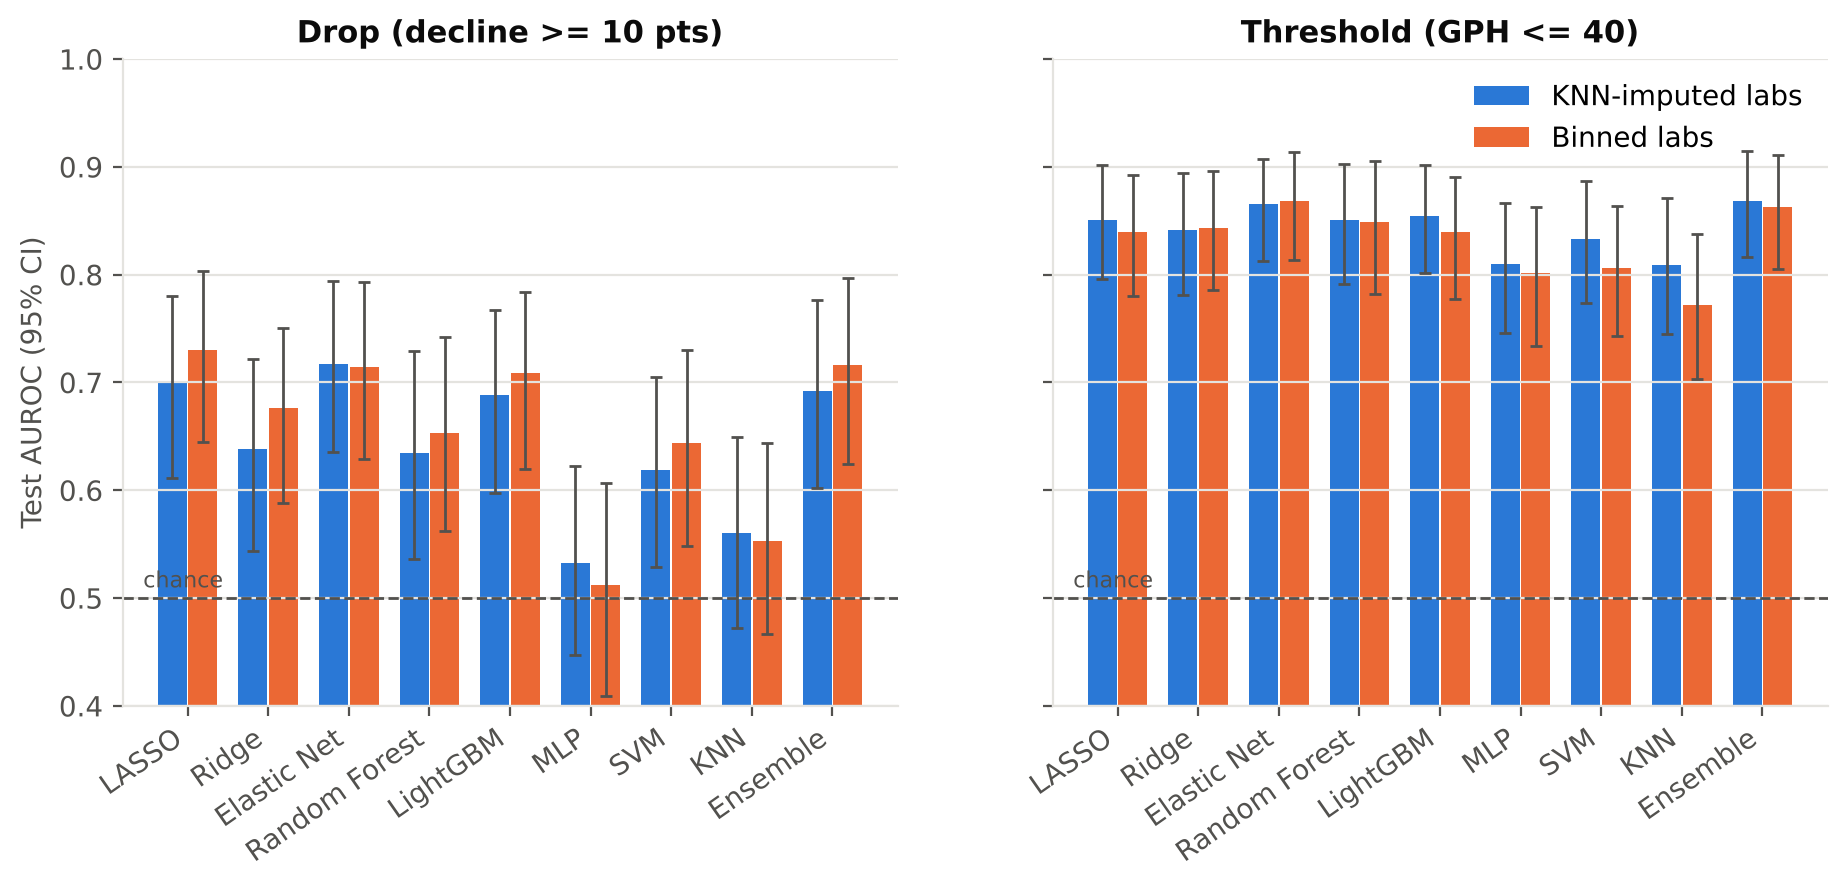

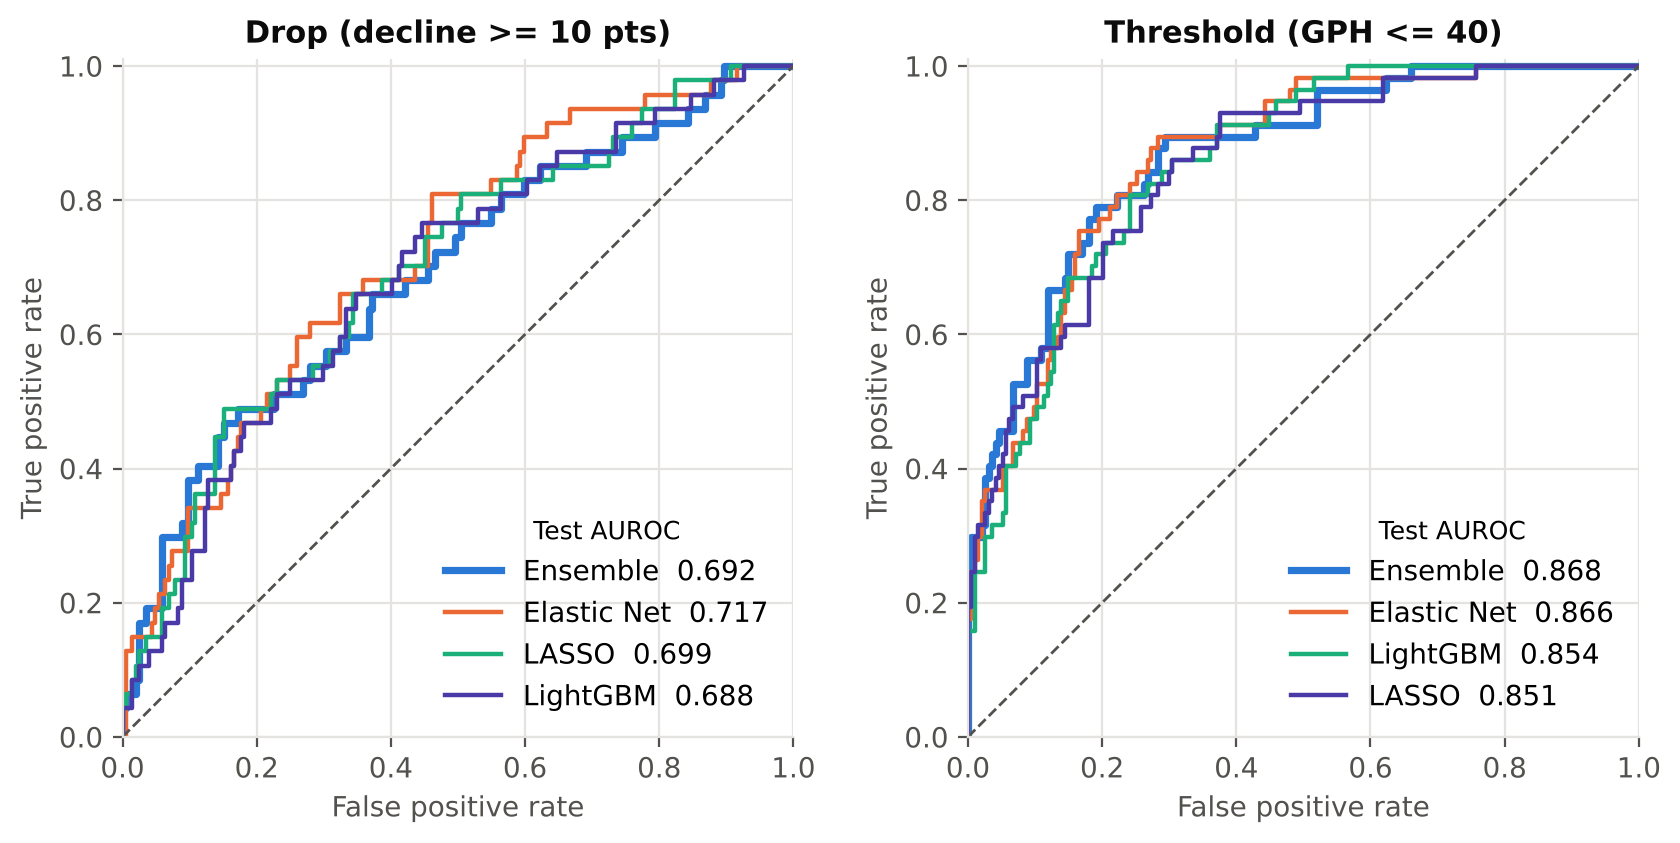

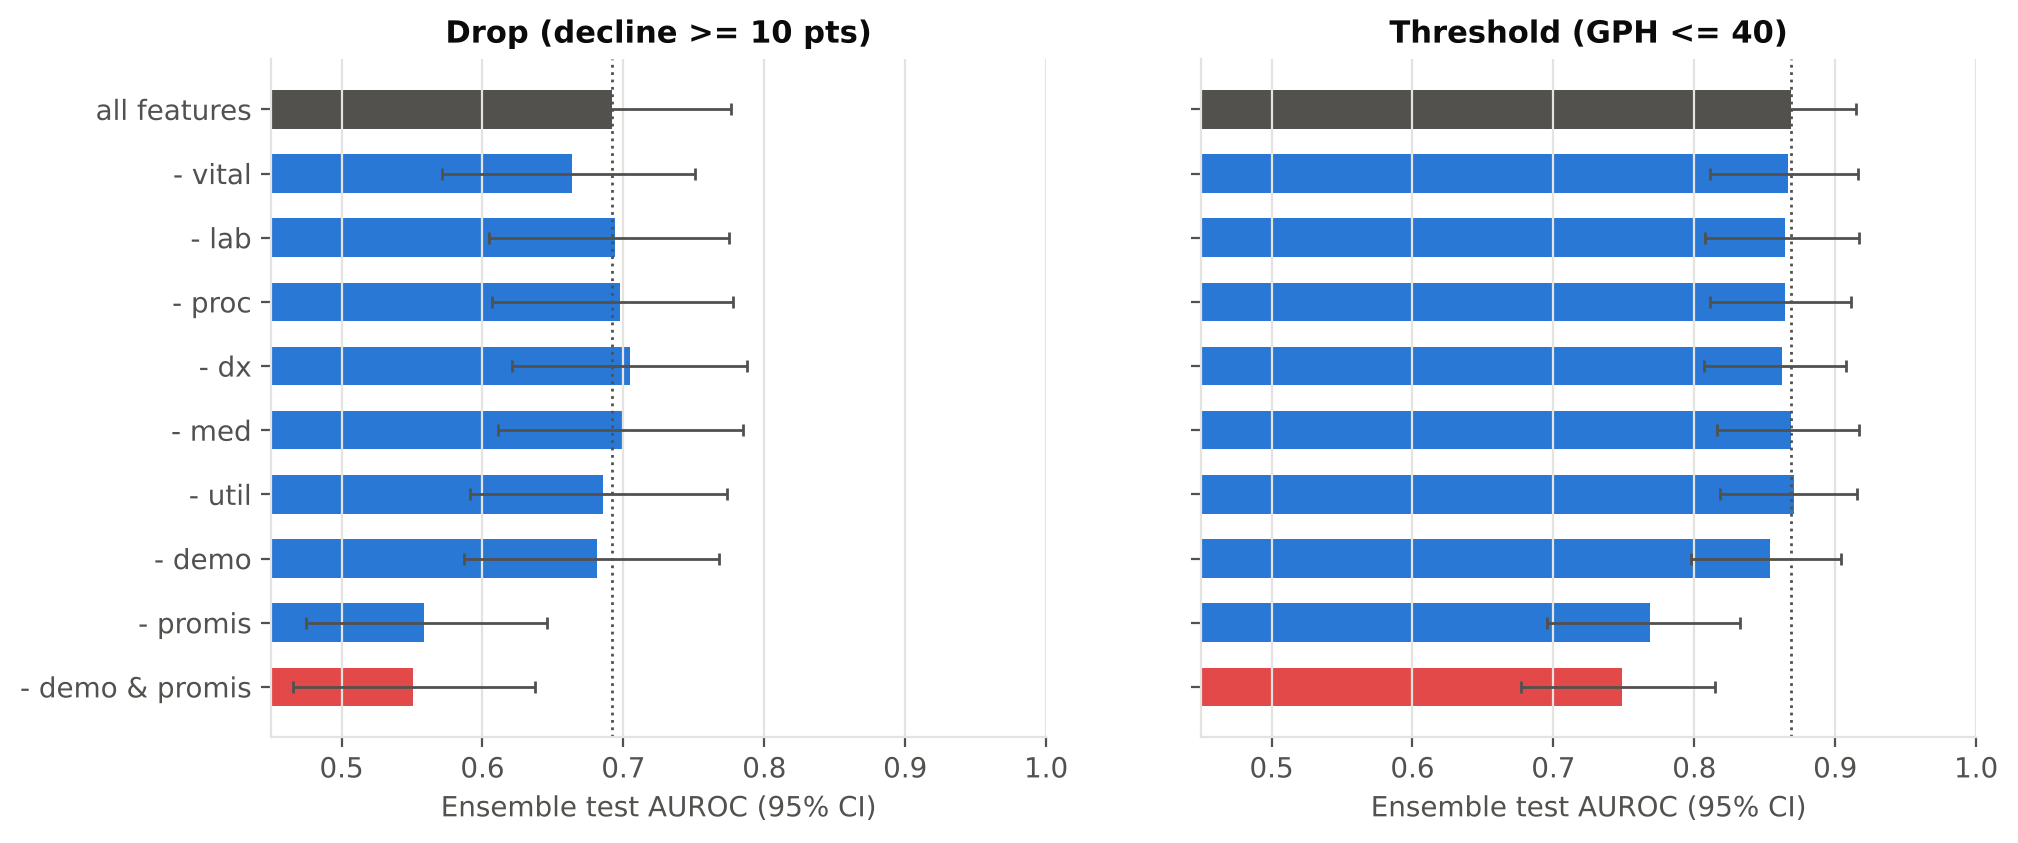

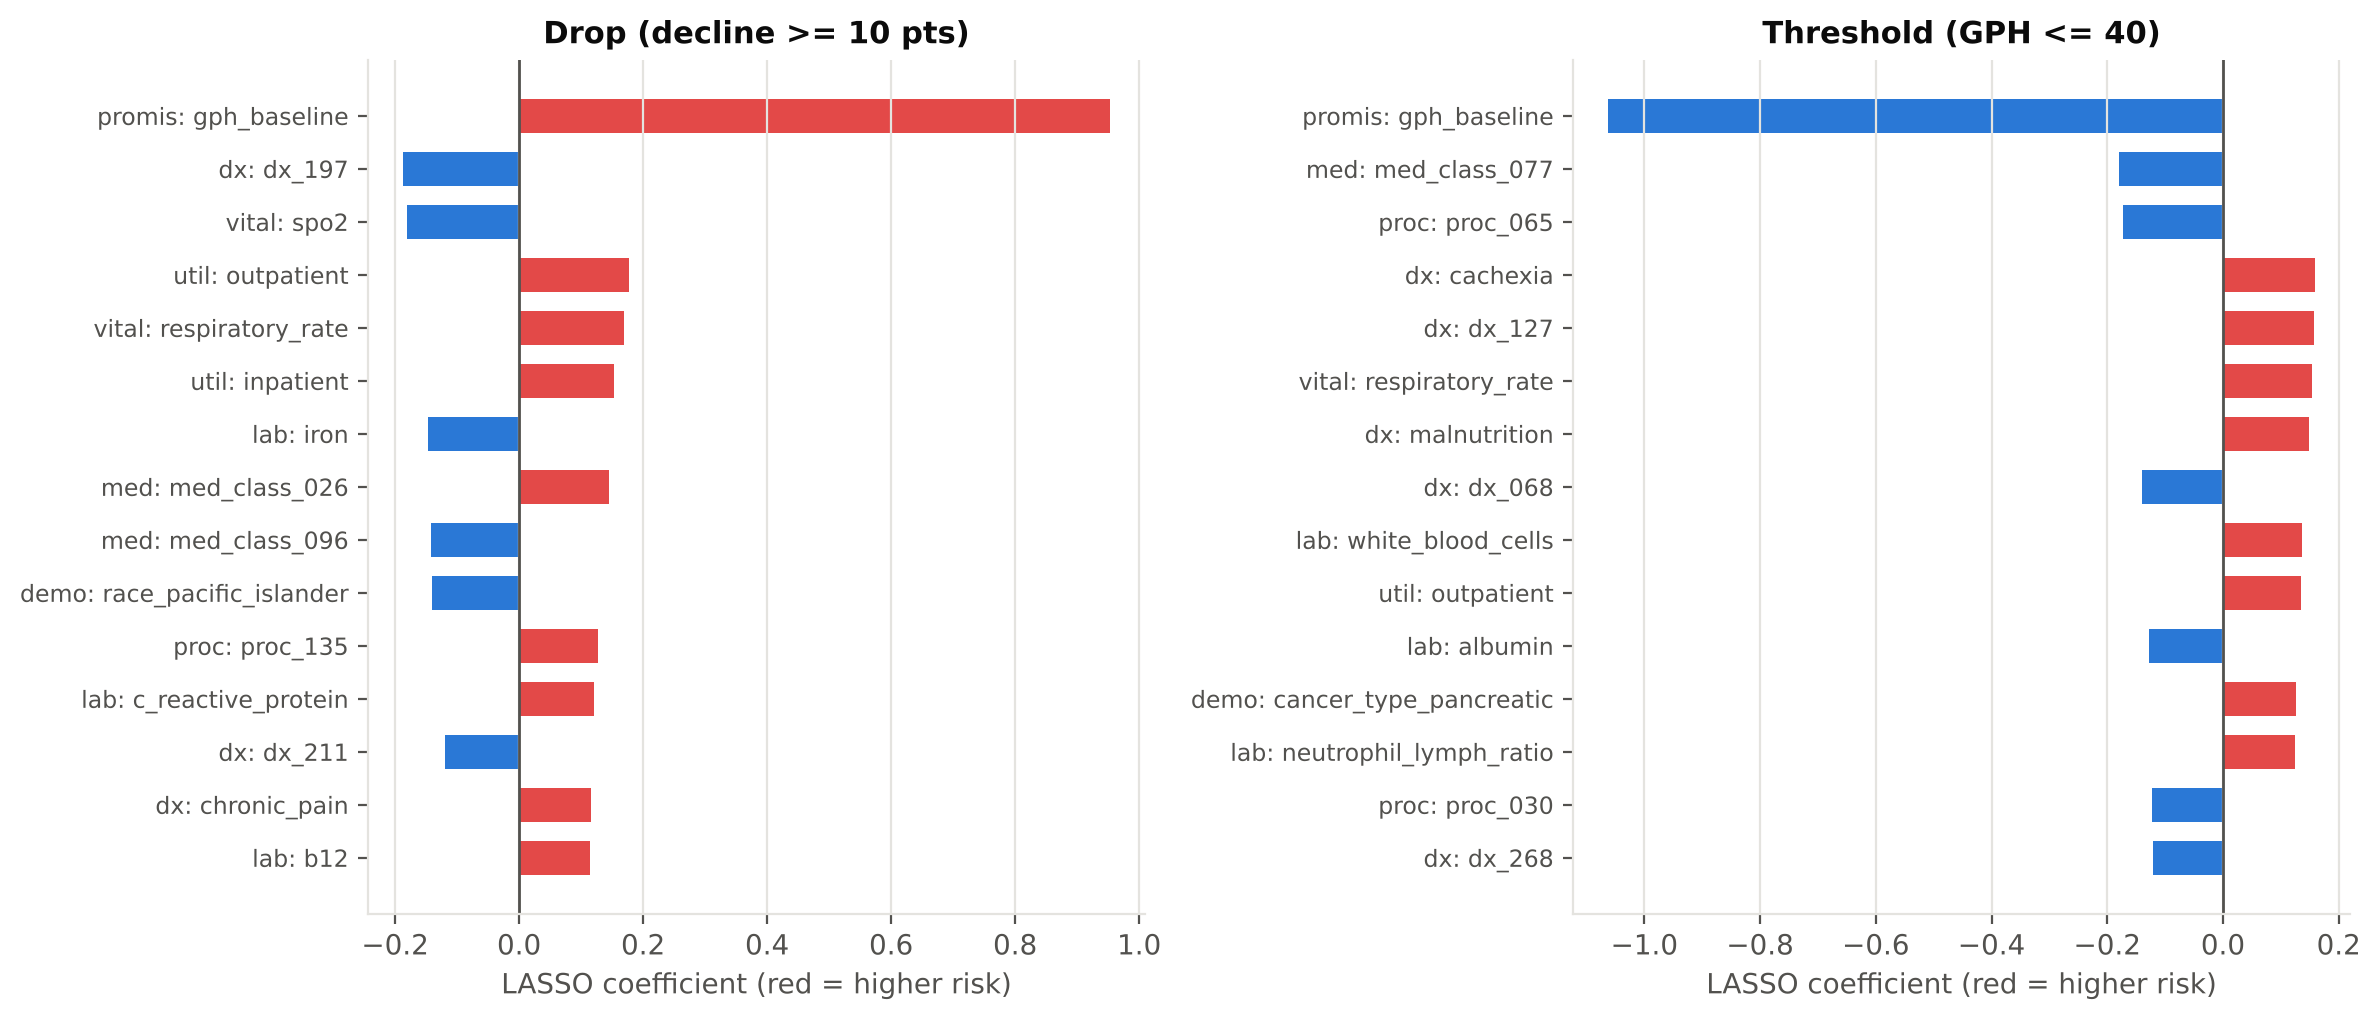

In [6]:
for f in ['model_comparison', 'roc_curves', 'ablation', 'top_features']:
    display(Image(filename=str(cfg.paths.figures_dir / f'{f}.png'), width=900))

## 5. Live scoring with the trained ensemble
Rank held-out patients by predicted risk of a *drop*; compare with what actually happened.

In [7]:
ens = joblib.load(cfg.paths.models_dir / 'drop__knn__ensemble.joblib')
risk = pd.Series(ens.predict_proba(X[te])[:, 1], index=X.index[te], name='predicted_risk')
print('Test AUROC:', round(roc_auc_score(cohort.loc[risk.index, 'drop'], risk), 3))
view = pd.concat([risk, X.loc[risk.index, ['demo__age', 'demo__cancer_type', 'promis__gph_baseline', 'lab__albumin']], cohort.loc[risk.index, ['gph_on_treatment', 'drop']]], axis=1)
view.sort_values('predicted_risk', ascending=False).head(10).round(2)

Test AUROC: 0.692


,predicted_risk,demo__age,demo__cancer_type,promis__gph_baseline,lab__albumin,gph_on_treatment,drop
patient_id,,,,,,,
P00722,0.54,56.9,leukemia,59.7,3.17,47.8,1
P01671,0.44,70.1,lung,67.5,NaN,52.2,1
P00728,0.42,37.0,sarcoma,57.7,NaN,48.8,0
P00731,0.40,60.2,breast,67.7,3.76,53.8,1
P00425,0.39,54.1,breast,67.7,NaN,59.0,0
P00388,0.38,47.5,leukemia,55.7,4.28,46.7,0
P01165,0.37,77.1,lymphoma,60.8,4.37,61.4,0
P01045,0.37,75.9,pancreatic,52.9,3.06,30.1,1
P00044,0.36,66.2,gastric,54.4,3.72,45.2,0


In [8]:
# Risk stratification: observed drop rate by predicted-risk quintile
q = pd.qcut(risk, 5, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])
cohort.loc[risk.index, 'drop'].groupby(q, observed=True).agg(['mean', 'size']).rename(columns={'mean': 'observed drop rate', 'size': 'n'}).round(3)

,observed drop rate,n
predicted_risk,,
Q1 (lowest),0.098,51
Q2,0.100,50
Q3,0.180,50
Q4,0.140,50
Q5 (highest),0.420,50


## 6. What-if: how does one patient's risk change?

In [9]:
pid = view.sort_values('predicted_risk').index[len(view) // 2]   # a median-risk patient
base = X.loc[[pid]]
rows = {'as recorded': base}
for label, col, val in [('albumin 2.8 g/dL', 'lab__albumin', 2.8),
                        ('baseline GPH 62', 'promis__gph_baseline', 62.0),
                        ('baseline GPH 35', 'promis__gph_baseline', 35.0)]:
    r = base.copy(); r[col] = val; rows[label] = r
pd.Series({k: ens.predict_proba(v)[0, 1] for k, v in rows.items()}, name='P(drop)').round(3)

as recorded         0.154
albumin 2.8 g/dL    0.200
baseline GPH 62     0.207
baseline GPH 35     0.077
Name: P(drop), dtype: float64

## 7. Retrain a model live (seconds)
Full pipeline (prevalence filter -> KNN imputation -> scaling -> LASSO) fitted on the training split only.

In [10]:
import json
from prodecline.models.registry import logistic
from prodecline.models.training import make_pipeline
best = json.loads((cfg.paths.results_dir / 'best_params.json').read_text())['drop/knn/lasso']
pipe = make_pipeline(logistic('lasso', cfg.train.seed), 'knn', cfg).set_params(clf__C=best['C'])
%time pipe.fit(X[tr], cohort['drop'][tr])
coef = pipe.named_steps['clf'].coef_.ravel()
print(f"best C={best['C']}: {(coef != 0).sum()} of {coef.size} features kept | test AUROC "
      f"{roc_auc_score(cohort['drop'][te], pipe.predict_proba(X[te])[:, 1]):.3f}")

CPU times: user 456 ms, sys: 27.9 ms, total: 484 ms
Wall time: 375 ms
best C=0.1: 163 of 538 features kept | test AUROC 0.699
